In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import os
import glob
import shutil

import numpy as np
import seaborn as sns
#
from dask.distributed import Client
import scipy.stats as sts
import xarray as xr
import dask
from pyhomogenize import open_xrdataset, save_xrdataset

from cmcrameri import cm
from cdo import *
cdo = Cdo()  
cdo.forceOutput = True
forceCDO = True

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

In [3]:
from plotting_tools_snow import *

In [4]:
home=os.getcwd()
# The data is quite large, therefore I use my work
database='/work/ch0636/g300047/SNOW-RESEARCH/HORIZONTAL-NA'

In [5]:
os.makedirs(database, exist_ok=True)
print(f"Directory ready: {database}")

Directory ready: /work/ch0636/g300047/SNOW-RESEARCH/HORIZONTAL-NA


# In the next two boxes you have to make a decision what you like to plot

In [11]:
# set directories for SNW
var='snw'
datadir=database+'/SNW-NA/'
#outdatadir=database+'/SNW-timeslice/'
outdatadir=database+'/SNW-timeslice/'
#tmpdir=database+'/tmp-snw/'
plotdir=database+'/plots/HORIZONTAL-SNW/'

## files are not always replace it seems, better delete outdatadir before running

In [12]:
directory_available(outdatadir)
directory_available(plotdir)
#directory_available(tmpdir)
print(plotdir)
print(outdatadir)


/work/ch0636/g300047/SNOW-RESEARCH/HORIZONTAL-NA/plots/HORIZONTAL-SNW/
/work/ch0636/g300047/SNOW-RESEARCH/HORIZONTAL-NA/SNW-timeslice/


Grid:

In [8]:
print('home: ',home)
griddir=home.replace('plotting-py/HORIZONTAL','grid')
grid=home.replace('plotting-py/HORIZONTAL','grid/EUR11-grid.txt')
griddir

home:  /home/g/g300047/SCRIPTS/github/snow-research/plotting_py/HORIZONTAL


'/home/g/g300047/SCRIPTS/github/snow-research/plotting_py/HORIZONTAL'

## Regridding
CNRM, ICTP, MPI-CSC:
Three regional climate simulation have not been provide on the regular EURO-CORDEX $0.11^\circ $ grid and had to be remapped. ALADIN63 and RegCM4-6 are remapped by using the CDO remapping method \textit{remapcon}. MPI-CSC-REMO2009 is on a shiftet EURO-CORDEX grid and is moved with \textit{cdo set grid} to the standard EURO-CORDEX $ 0.11^\circ $ grid.

### If you have conducted remapping, you do not need to do it again , files are saved

Regridding is now run in a batch job, because it is too time consuming for a notebook

    sbatch run_regrid.sh

This is calling remap_euro_cordex.py, where the path and variable must get adjusted.

### Path is set in batch script

## RESULTS of remap are in:
/work/ch0636/g300047/SNOW-RESEARCH/HORIZONTAL-NA/SNOWDAY-NA

/work/ch0636/g300047/SNOW-RESEARCH/HORIZONTAL-NA/SNW-NA


Calculation the time slice and signifgicance take a long time, so it is outsourced to a batch script and you need to split the amount of files. I ran the script for each scenario.

    sbatch run_timeslice.sh
This uses timeslice_euro_cordex.py where you have to adjust PATH and VAR.

Again this is done in a batch job

    sbatch run_ensemble.sh
which is using ensemblemean_exp.py

In [13]:
print(plotdir)
outdatadir
#outdatadir='/work/ch0636/g300047/SNOW-RESEARCH/HORIZONTAL-NA/SNW-timeslice-pro'


/work/ch0636/g300047/SNOW-RESEARCH/HORIZONTAL-NA/plots/HORIZONTAL-SNW/


'/work/ch0636/g300047/SNOW-RESEARCH/HORIZONTAL-NA/SNW-timeslice/'

### Colors for snow days

### Colors for snw

In [ ]:
# von Christian
# Levels and colormap for snow water equivalent [mm]
from cmocean.cm import ice_r, matter

levels_cm_swe = {
    "levels": np.array([0.0, 5.0, 10.0, 20.0, 30.0, 40.0, 60.0, 80.0, 100.0,
                        140.0, 180.0, 220.0, 260.0, 300.0]),
    "ticks": np.array([0, 5, 10, 20, 30, 40, 60, 80, 100,
                       140, 180, 220, 260, 300]),
    "cm": ListedColormap(
        ["white",
         ice_r(0.1),
         ice_r(0.2),
         ice_r(0.3),
         ice_r(0.4),
         ice_r(0.5),
         ice_r(0.6),
         ice_r(0.7),
         ice_r(0.8),
         ice_r(0.9),
         matter(0.9),
         matter(0.8),
         matter(0.7),
         matter(0.6)])
}
levels_cm_swe["cm"].set_bad(color="lightgrey")


In [ ]:
levels_cm_swe

In [14]:
#snw-diff
level_snw_steps_diff=[-200,-150,-100,-50,-40,-30,-20,-10,-1,1,10,20,30,40,50]
level_snw_steps_diff_pro=[-20,-15,-10,-5,-4,-3,-2,-1,0]
#old colorbar:
#colors_snw_diff = ['#3f007d', '#081d58', '#253494','#225ea8', '#1d91c0', '#41b6c4', '#7fcdbb', '#c7e9b4', '#edf8b1', '#ffffff']
               #'#f0f0f0']
#newcolors
colors_snw_diff=['#800026','#bd0026','#e31a1c','#fc4e2a','#fd8d3c','#feb24c','#fed976',
                 '#ffeda0','#ffffcc','#ffffff', '#ffffff' ,'#c7e9b4','#7fcdbb','#41b6c4','#1d91c0','#253494','#081d58']
plotdir='/work/ch0636/g300047/SNOW-RESEARCH/HORIZONTAL-NA/plots/HORIZONTAL-SNW_newcolor/'
directory_available(plotdir)


colors_snw_diff_cmap = ListedColormap(colors_snw_diff)
colors_snw_diff_cmap.set_bad(color="lightgrey")

#color_steps.set_under(color="white")

In [32]:
level_snw_steps_diff = [-200, -150, -100, -50, -40, -30, -20, -10, -1,0,
                         1, 10, 20, 30, 40]

colors_snw_diff = [
    # Negative changes: red shades
    "#800026", "#bd0026", "#e31a1c", "#fc4e2a",
    "#fd8d3c", "#feb24c", "#fed976", "#ffeda0",
    # Near-zero interval
    "#ffffff",
    # Positive changes: light to dark blue
    "#c6dbef", "#6baed6", "#3182bd", "#08519c", "#08306b",
]

colors_snw_diff_cmap = ListedColormap(colors_snw_diff)
colors_snw_diff_cmap.set_bad(color="lightgrey")

2021-2050
Plot saved: /work/ch0636/g300047/SNOW-RESEARCH/HORIZONTAL-NA/plots/HORIZONTAL-SNW_newcolor//ensemble_mean_diff_snw_ensemble_diff_2021-2050.png
2069-2098
Plot saved: /work/ch0636/g300047/SNOW-RESEARCH/HORIZONTAL-NA/plots/HORIZONTAL-SNW_newcolor//ensemble_mean_diff_snw_ensemble_diff_2069-2098.png


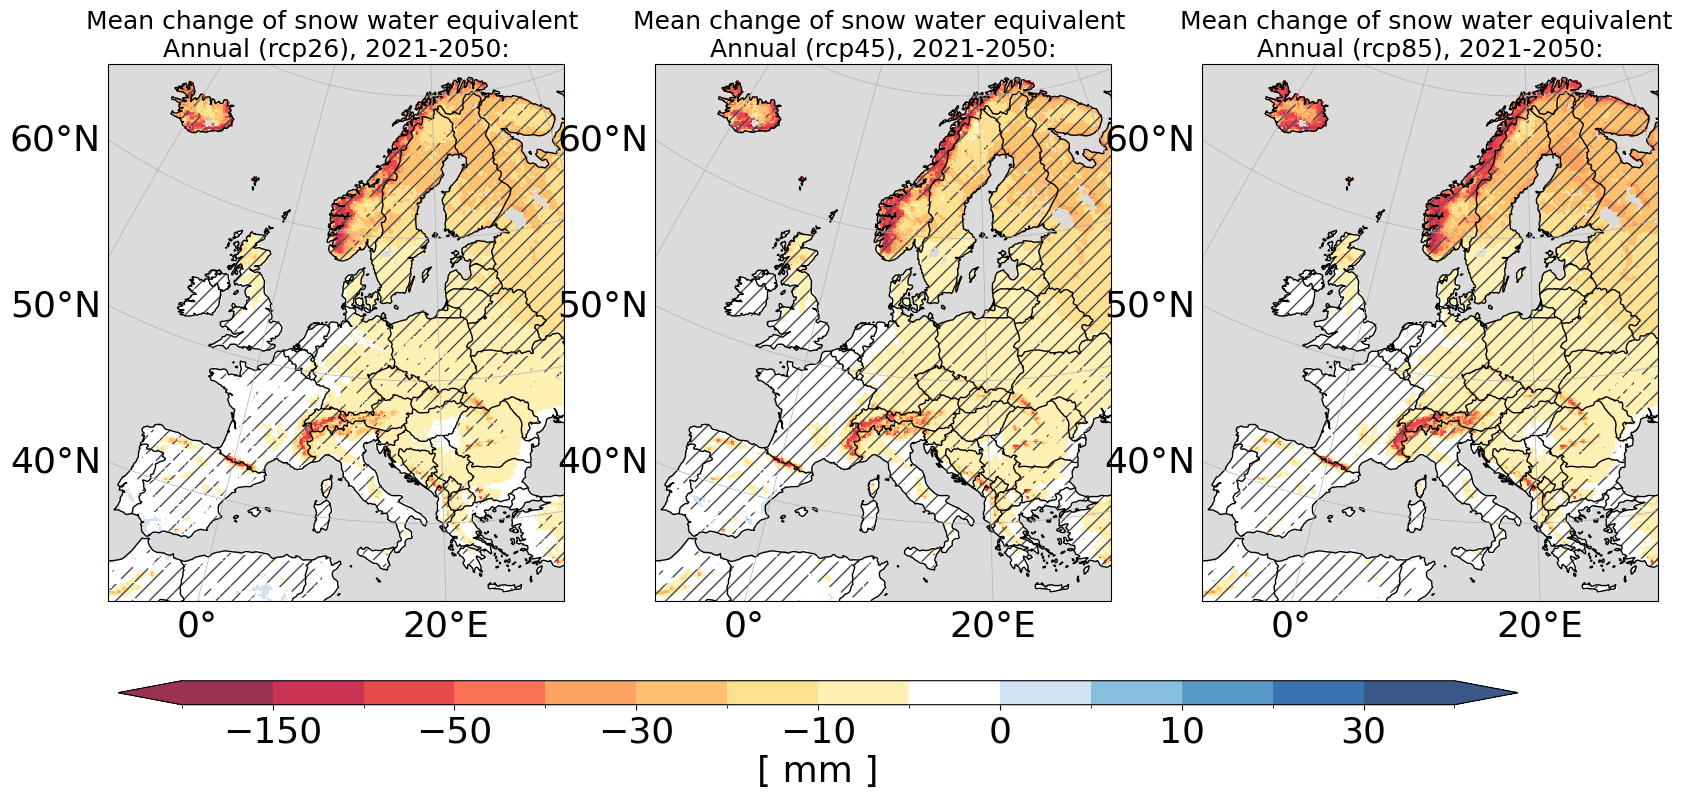

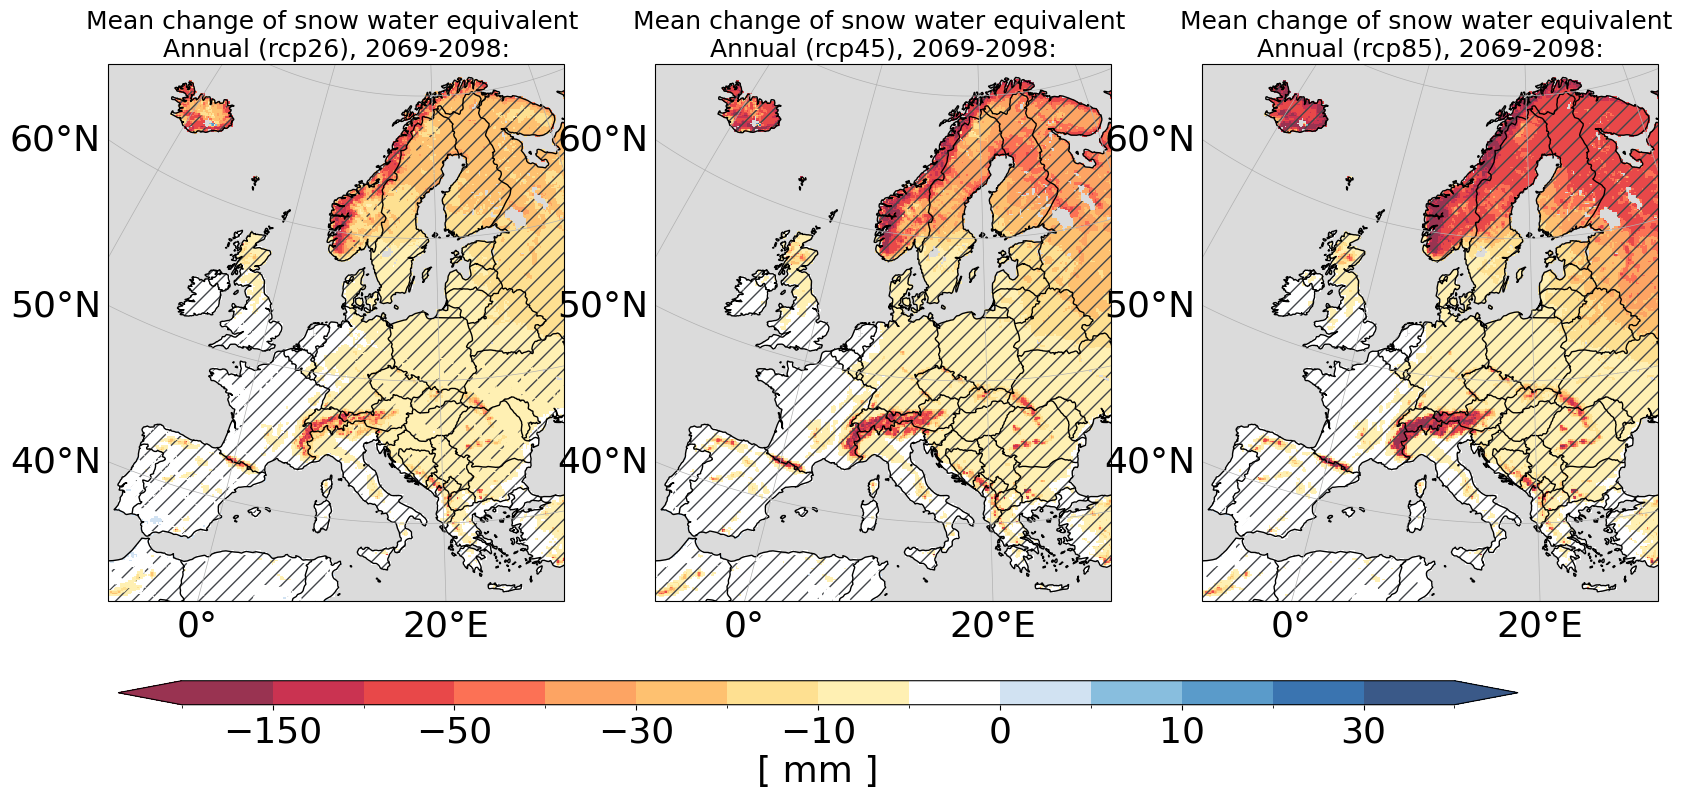

In [33]:
# plot3 for diff:
# editing the variable you like to plot 
# is needed in the line below. 
# You can choose between "snw_ensemble_diff" and "sd_ensemble_diff"

if var =='snw':
    vardiff="snw_ensemble_diff"
    unit='[ mm ]'
elif var =='sd':
    vardiff="snw_ensemble_diff" # the variable should be sd, but somehow did not get changed in the netcdf files. Therefore, I use snw_ensemble_diff for sd as well.
    unit='[ days / mon ]'

for timeslice in ('2022_2051', '2070_2099'):
    file1=outdatadir+'/ENS_ROBUSTNESS_'+timeslice+'_rcp26.nc'
    file2=outdatadir+'/ENS_ROBUSTNESS_'+timeslice+'_rcp45.nc'
    file3=outdatadir+'/ENS_ROBUSTNESS_'+timeslice+'_rcp85.nc'
    #file1=outdatadir+'/ENS_ROBUSTNESS_'+timeslice+'_rcp26.nc'
    #file2=outdatadir+'/ENS_ROBUSTNESS_'+timeslice+'_rcp45.nc'
    #file3=outdatadir+'/ENS_ROBUSTNESS_'+timeslice+'_rcp85.nc'
    ds1 = xr.open_mfdataset(file1, decode_times=False)
    ds2 = xr.open_mfdataset(file2, decode_times=False)
    ds3 = xr.open_mfdataset(file3, decode_times=False)
    if timeslice == '2022_2051':
        time=timeslice.replace('2022_2051','2021-2050')
    else:
        time=timeslice.replace('2070_2099','2069-2098')
    print(time)
    ds_dict = {
    "rcp26_"+time: ds1,   
    "rcp45_"+time: ds2,    
    "rcp85_"+time: ds3,
        }
    
    plot_3(
        ds_dict,
        var=vardiff,
        unit=unit,
        mode="diff",
        colors=colors_snw_diff_cmap,
        levels=level_snw_steps_diff,
        robustness=True,
        add_cbar=True,
        # black hatchcolor="#020202"
        hatchcolor="#43464B",
        output_path=plotdir,
        extend="both",#"max",
    )

In [34]:
#plot 3 for absolut:
if var =='snw':
    unit='[ mm ]'
    colorsteps=levels_cm_swe["cm"]
    levelsteps=levels_cm_swe["levels"]
elif var =='sd':
    var='snw' # because sd is calculated from snw, the vriable did not get changed during data processing. Therefore, I use snw for sd as well.
    unit='[ days / mon ]'
    colorsteps=color_steps
    levelsteps=level_steps

for timeslice in ('1972_2001', '2022_2051', '2070_2099'):
    file1=outdatadir+'/ENS_MEAN_'+timeslice+'_rcp26.nc'
    file2=outdatadir+'/ENS_MEAN_'+timeslice+'_rcp45.nc'
    file3=outdatadir+'/ENS_MEAN_'+timeslice+'_rcp85.nc'
    ds1 = xr.open_mfdataset(file1, decode_times=False)
    ds2 = xr.open_mfdataset(file2, decode_times=False)
    ds3 = xr.open_mfdataset(file3, decode_times=False)
    if timeslice == '1972_2001':
        time=timeslice.replace('1972_2001','1971-2000')
    elif timeslice == '2022_2051':
        time=timeslice.replace('2022_2051','2021-2050')
    else:
        time=timeslice.replace('2070_2099','2069-2098')
    print(time)
    ds_dict = {
    "rcp26_"+time: ds1,
    "rcp45_"+time: ds2,
    "rcp85_"+time: ds3,
        }
    #ds_dict
    plot_3(
        ds_dict,
        var=var,
        mode="absolut",
        unit=unit,
        #colors=levels_cm_swe["cm"],
        #levels=levels_cm_swe["levels"],
        colors=colorsteps,
        levels=levelsteps,
        robustness=False,
        add_cbar=True,
        # black hatchcolor="#020202"
        hatchcolor="#43464B",
        output_path=plotdir,
        extend="max",
    )

NameError: name 'levels_cm_swe' is not defined

In [35]:
file4=outdatadir+'/ENS_ROBUSTNESS_2022_2051_rcp26.nc'
file5=outdatadir+'/ENS_ROBUSTNESS_2022_2051_rcp45.nc'
file6=outdatadir+'/ENS_ROBUSTNESS_2022_2051_rcp85.nc'
file7=outdatadir+'/ENS_ROBUSTNESS_2070_2099_rcp26.nc'
file8=outdatadir+'/ENS_ROBUSTNESS_2070_2099_rcp45.nc'
file9=outdatadir+'/ENS_ROBUSTNESS_2070_2099_rcp85.nc'
ds4 = xr.open_mfdataset(file4, decode_times=False)
ds5 = xr.open_mfdataset(file5, decode_times=False)
ds6 = xr.open_mfdataset(file6, decode_times=False)
ds7 = xr.open_mfdataset(file7, decode_times=False)
ds8 = xr.open_mfdataset(file8, decode_times=False)
ds9 = xr.open_mfdataset(file9, decode_times=False)
ds_dict3 = {
    "rcp26_2021-2050": ds4,
    "rcp45_2021-2050": ds5,
    "rcp85_2021-2050": ds6,
        }

ds_dict3["rcp26_2069-2098"] = ds7
ds_dict3["rcp45_2069-2098"] = ds8
ds_dict3["rcp85_2069-2098"] = ds9

In [41]:
plotdir

'/work/ch0636/g300047/SNOW-RESEARCH/HORIZONTAL-NA/plots/HORIZONTAL-SNW_newcolor/'

<module 'matplotlib.pyplot' from '/work/ch0636/g300047/.conda/envs/snow/lib/python3.13/site-packages/matplotlib/pyplot.py'>

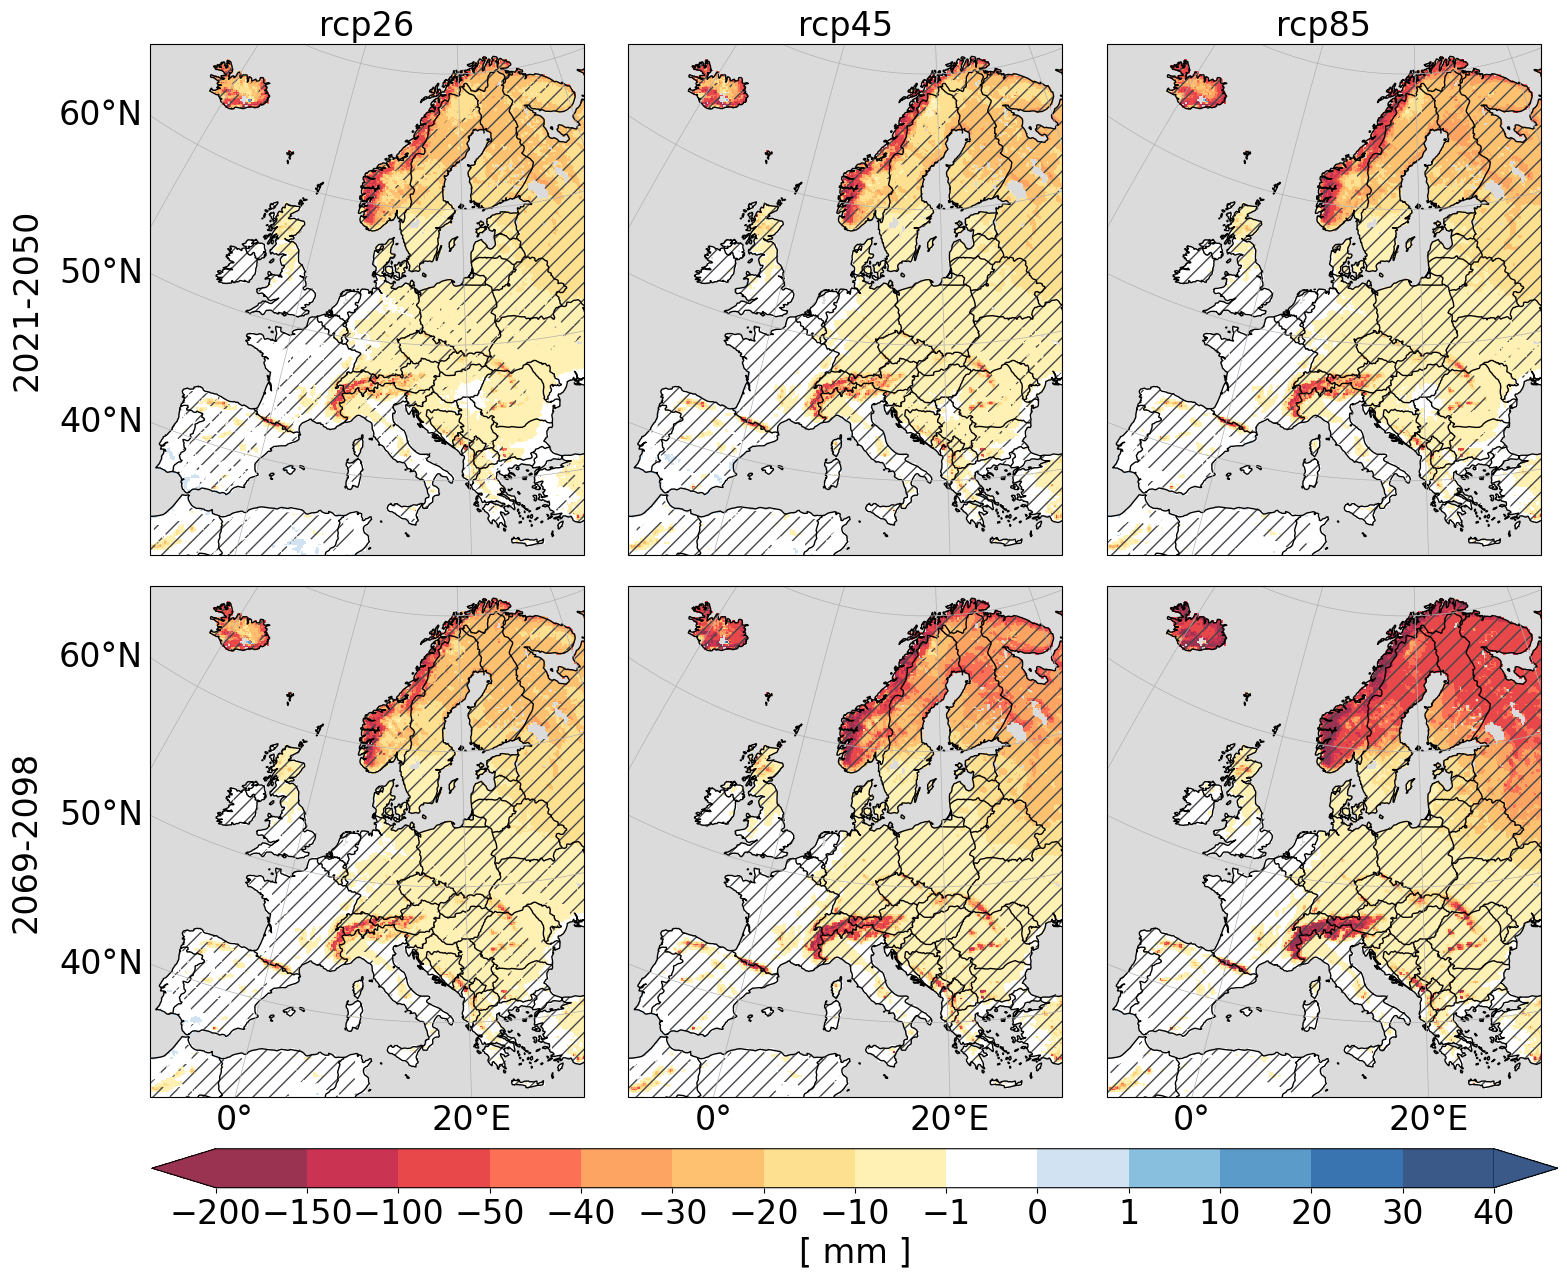

In [40]:
if var =='snw':
    vardiff="snw_ensemble_diff"
    unit='[ mm ]'
    colors_diff_cmap=colors_snw_diff_cmap
    level_steps_diff=level_snw_steps_diff
#if var =='sd':
#    vardiff="snw_ensemble_diff"
#    unit='[ days / mon ]'
#    colors_diff_cmap=colors_diff_cmap
#    level_steps_diff=level_steps_diff

plot_6(
    ds_dict3,
    var=vardiff,
    mode="diff",
    colors=colors_diff_cmap,
    levels=level_steps_diff,
    robustness=True,
    add_cbar=True,
        # black hatchcolor="#020202"
    hatchcolor="#43464B",
    output_path=plotdir,
    extend="both",#"neither",
    )

In [36]:
file1=outdatadir+'/ENS_MEAN_1972_2001_rcp26.nc'
file2=outdatadir+'/ENS_MEAN_1972_2001_rcp45.nc'
file3=outdatadir+'/ENS_MEAN_1972_2001_rcp85.nc'
file4=outdatadir+'/ENS_MEAN_2022_2051_rcp26.nc'
file5=outdatadir+'/ENS_MEAN_2022_2051_rcp45.nc'
file6=outdatadir+'/ENS_MEAN_2022_2051_rcp85.nc'
file7=outdatadir+'/ENS_MEAN_2070_2099_rcp26.nc'
file8=outdatadir+'/ENS_MEAN_2070_2099_rcp45.nc'
file9=outdatadir+'/ENS_MEAN_2070_2099_rcp85.nc'
ds1 = xr.open_mfdataset(file1, decode_times=False)
ds2 = xr.open_mfdataset(file2, decode_times=False)
ds3 = xr.open_mfdataset(file3, decode_times=False)
ds4 = xr.open_mfdataset(file4, decode_times=False)
ds5 = xr.open_mfdataset(file5, decode_times=False)
ds6 = xr.open_mfdataset(file6, decode_times=False)
ds7 = xr.open_mfdataset(file7, decode_times=False)
ds8 = xr.open_mfdataset(file8, decode_times=False)
ds9 = xr.open_mfdataset(file9, decode_times=False)
ds_dict2 = {
    "rcp26_1971-2000": ds1,
    "rcp45_1971-2000": ds2,
    "rcp85_1971-2000": ds3,
        }
ds_dict2["rcp26_2021-2050"] = ds4
ds_dict2["rcp45_2021-2050"] = ds5
ds_dict2["rcp85_2021-2050"] = ds6
ds_dict2["rcp26_2069-2098"] = ds7
ds_dict2["rcp45_2069-2098"] = ds8
ds_dict2["rcp85_2069-2098"] = ds9

In [38]:
var='sd'

Plot saved: /work/ch0636/g300047/SNOW-RESEARCH/HORIZONTAL-NA/plots/HORIZONTAL-SD_newcolor//ensemble_mean_snw_all_oTT.png


<module 'matplotlib.pyplot' from '/work/ch0636/g300047/.conda/envs/snow/lib/python3.13/site-packages/matplotlib/pyplot.py'>

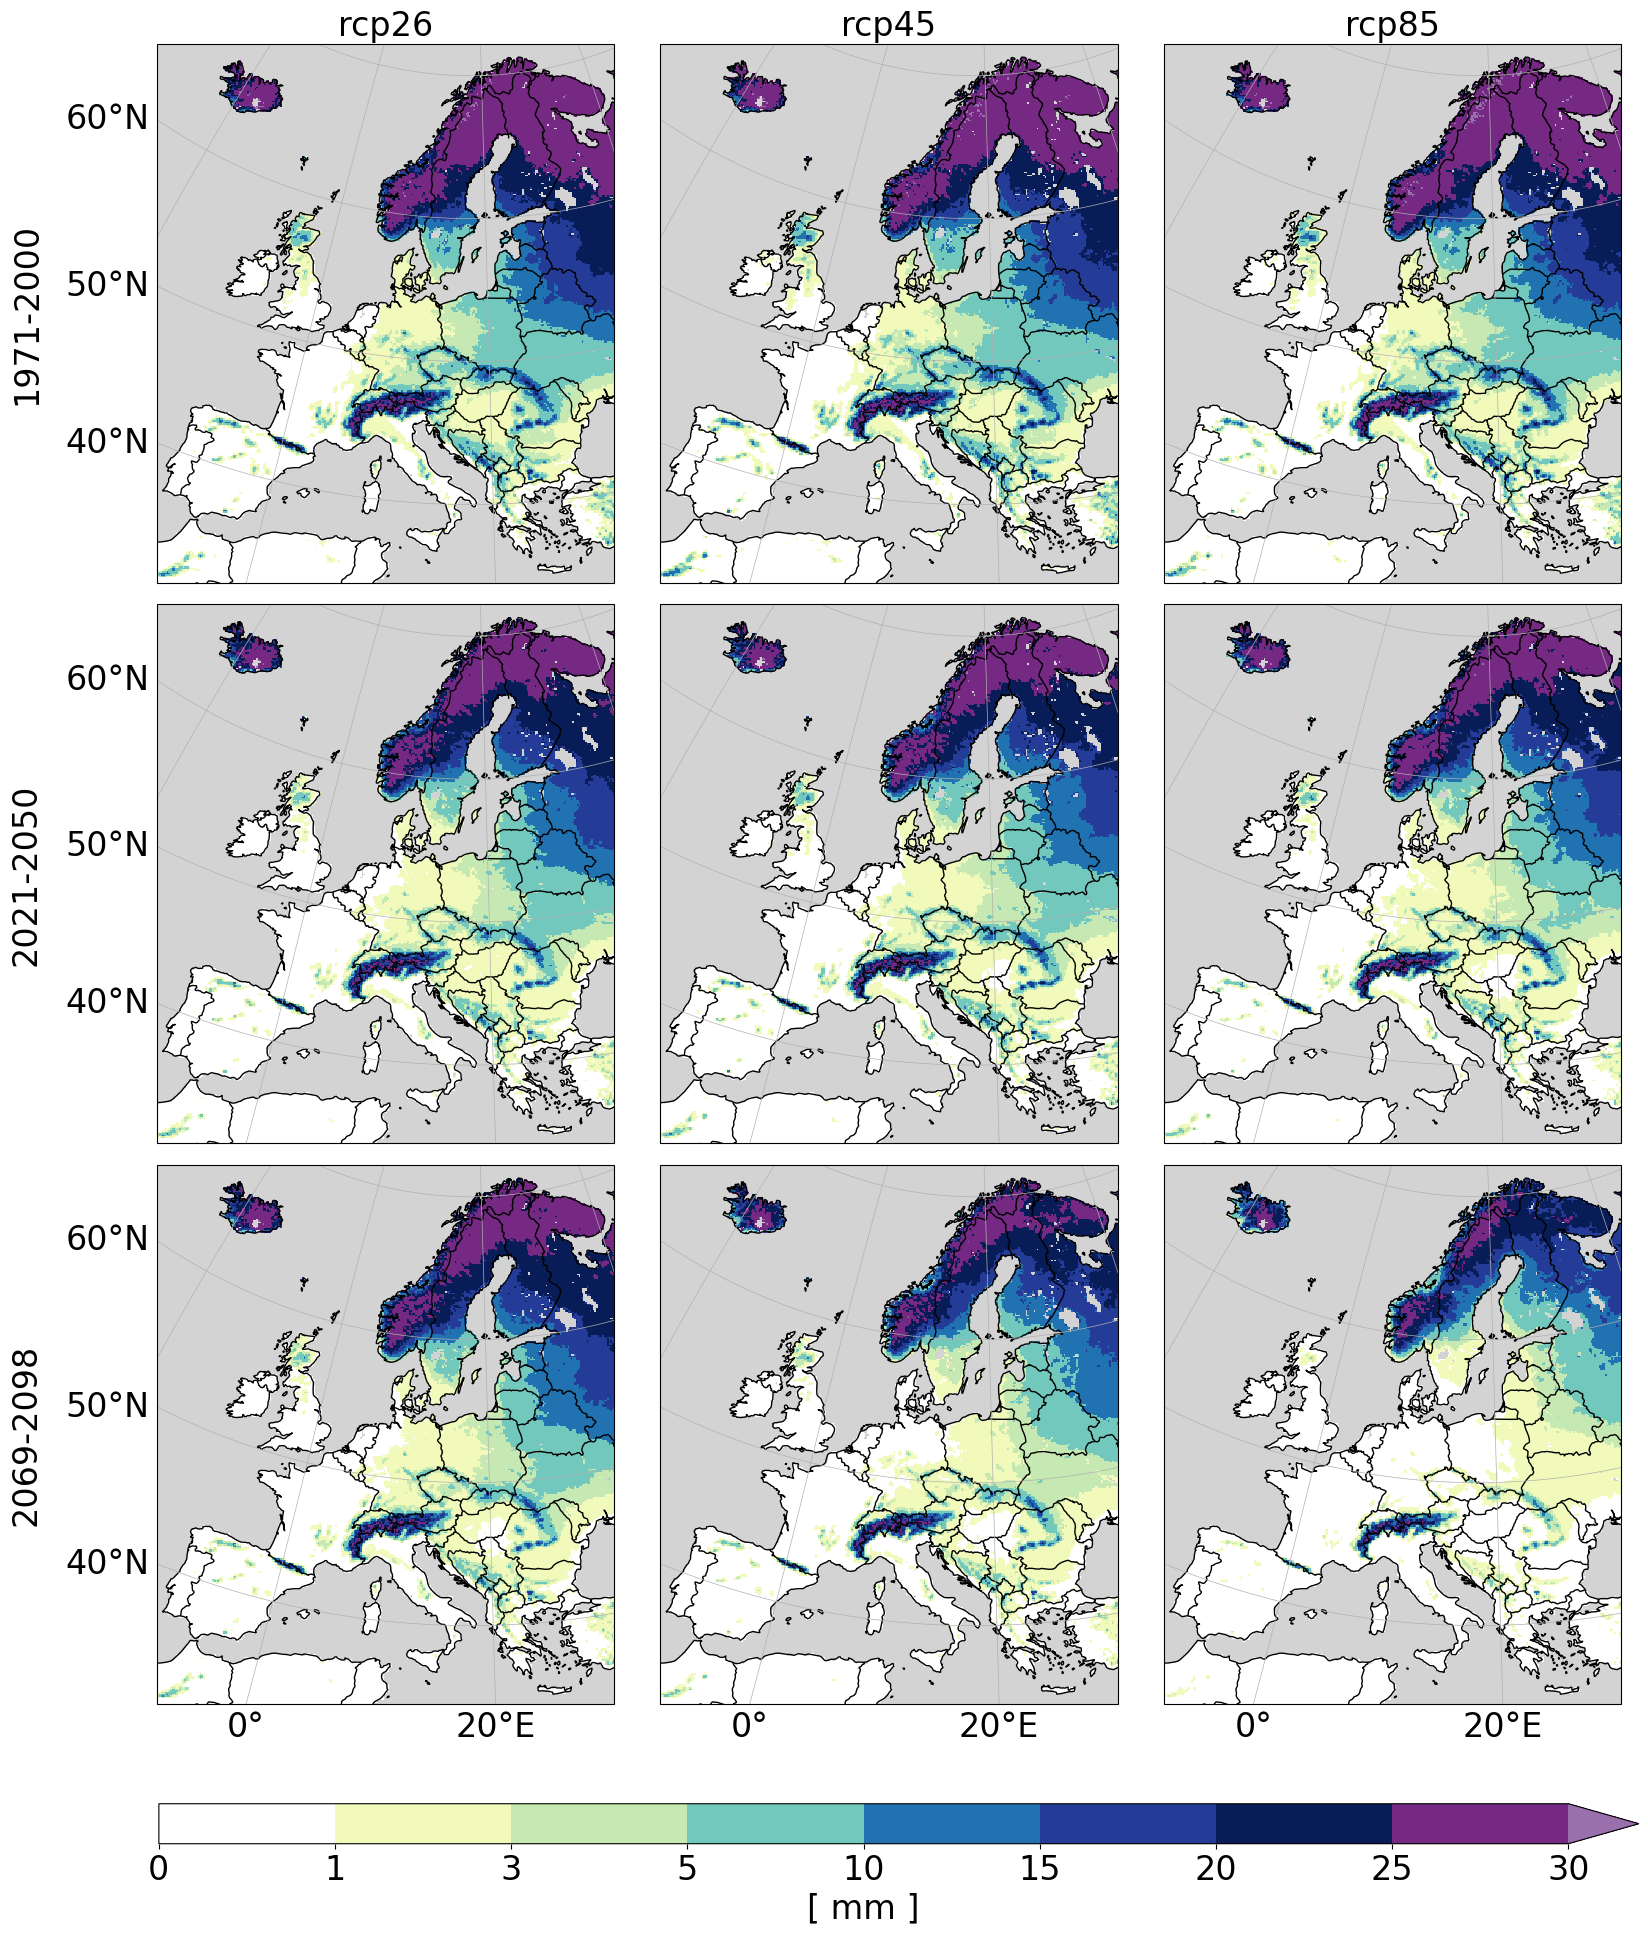

In [40]:
if var =='snw':
    colorsteps=levels_cm_swe["cm"]
    levelsteps=levels_cm_swe["levels"]
elif var == 'sd':
    var='snw'
    colorsteps=color_steps
    levelsteps=level_steps

plot_9(
    ds_dict2,
    var=var,
    mode="absolut",
    #colors=levels_cm_swe["cm"],
    #levels=levels_cm_swe["levels"],
    colors=colorsteps,
    levels=levelsteps,
    #robustness=False,
    add_cbar=True,
    #hatchcolor="#43464B",
    output_path=plotdir,
    extend="max",
    )
